# Tech jobs in Toronto: what a year of Job Bank postings says

A plain-language summary for job seekers and anyone without a data background. It answers five questions
with the official postings published on Canada's National Job Bank between November 2025 and October 2026.
Each answer comes first in words, followed by the table or chart it is based on. The code cells only load
the results and can be skipped.

**What this data is, and is not.** Job Bank is the federal government's job board. Many tech employers,
especially large tech companies, advertise mainly on LinkedIn and their own sites, so this is the market
*as seen on Job Bank*, not the whole market. "Toronto" means Statistics Canada's Toronto Region, which also
includes cities such as Mississauga and Brampton. The full method is in the
[README](../README.md) and the SQL queries in [`src/jobmarket/sql/analysis`](../src/jobmarket/sql/analysis).

In [1]:
import os
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from jobmarket.analysis import run_analysis
from jobmarket.charts import CHARTS

# Build the database first with `jobmarket download` and `jobmarket build` (see the README).
DB = Path(os.environ.get("JOBMARKET_DB", "../data/jobmarket.duckdb"))
tables = {table.name: table for table in run_analysis(duckdb.connect(str(DB), read_only=True))}
FIGURES = Path(tempfile.mkdtemp())  # the images are embedded in the notebook itself


def number(value):
    """Whole numbers with thousands separators, shares with one decimal."""
    if isinstance(value, float):
        return f"{value:,.0f}" if value.is_integer() else f"{value:,.1f}"
    if isinstance(value, int):
        return f"{value:,}"
    return value


def show(name, columns=None, rename=None):
    """Display one analysis table, optionally with fewer and friendlier columns."""
    table = tables[name]
    frame = pd.DataFrame(table.rows, columns=table.columns)
    if columns:
        frame = frame[columns]
    display(frame.rename(columns=rename or {}).style.hide(axis="index").format(number))


def chart(name):
    """Draw the project's chart for one table and show it."""
    draw, filename = CHARTS[name]
    path = draw(tables[name], FIGURES / filename)
    plt.close("all")  # show the saved image only, not a second inline copy
    display(Image(filename=str(path)))


overview = dict(zip(tables["01_overview"].columns, tables["01_overview"].rows[0], strict=True))
print(
    f"{overview['tech_postings']:,} distinct tech postings in Canada, "
    f"{overview['toronto_tech_postings']:,} of them in the Toronto Region, "
    f"over {overview['months']} months."
)

11,025 distinct tech postings in Canada, 5,074 of them in the Toronto Region, over 12 months.


## 1. Where are the tech jobs?

**About half of Canada's tech postings on Job Bank are in the Toronto Region.** For data roles the share is
55%, and for software 51%. Network and support roles are the exception: only 29% are in Toronto, so they
are spread more evenly across the country.

In [2]:
show(
    "02_toronto_share_by_family",
    rename={
        "family": "Family",
        "canada_postings": "Canada",
        "toronto_postings": "Toronto Region",
        "toronto_share_pct": "Toronto share (%)",
    },
)

Family,Canada,Toronto Region,Toronto share (%)
IT & systems,"3,450","1,657",48
Software,"3,142","1,596",50.8
Networks & support,"1,815",534,29.4
Data,"1,201",655,54.5
Web,866,368,42.5
Security,551,264,47.9


The most advertised tech jobs in the Toronto Region are information systems specialists (1,381 postings),
software developers (909), software engineers (621) and data scientists (421).

In [3]:
show(
    "04_toronto_top_occupations",
    columns=["occupation", "postings", "median"],
    rename={"occupation": "Occupation", "postings": "Postings", "median": "Median salary (CAD)"},
)

Occupation,Postings,Median salary (CAD)
Information systems specialists,"1,381","92,600"
Software developers and programmers,909,"111,200"
Software engineers and designers,621,"122,800"
Data scientists,421,"103,700"
Web developers and programmers,315,"83,200"
Business systems specialists,276,"93,300"
Cybersecurity specialists,264,"104,300"
User support technicians,206,"66,400"
Computer network and web technicians,203,"75,000"
Database analysts and data administrators,163,"89,500"


## 2. What do they pay?

The **median** is the middle salary: half of the postings offer more, half offer less. Across all postings,
the median is higher in Toronto than in the rest of Canada for every tech family, for example $117,500 versus
$92,500 for software.

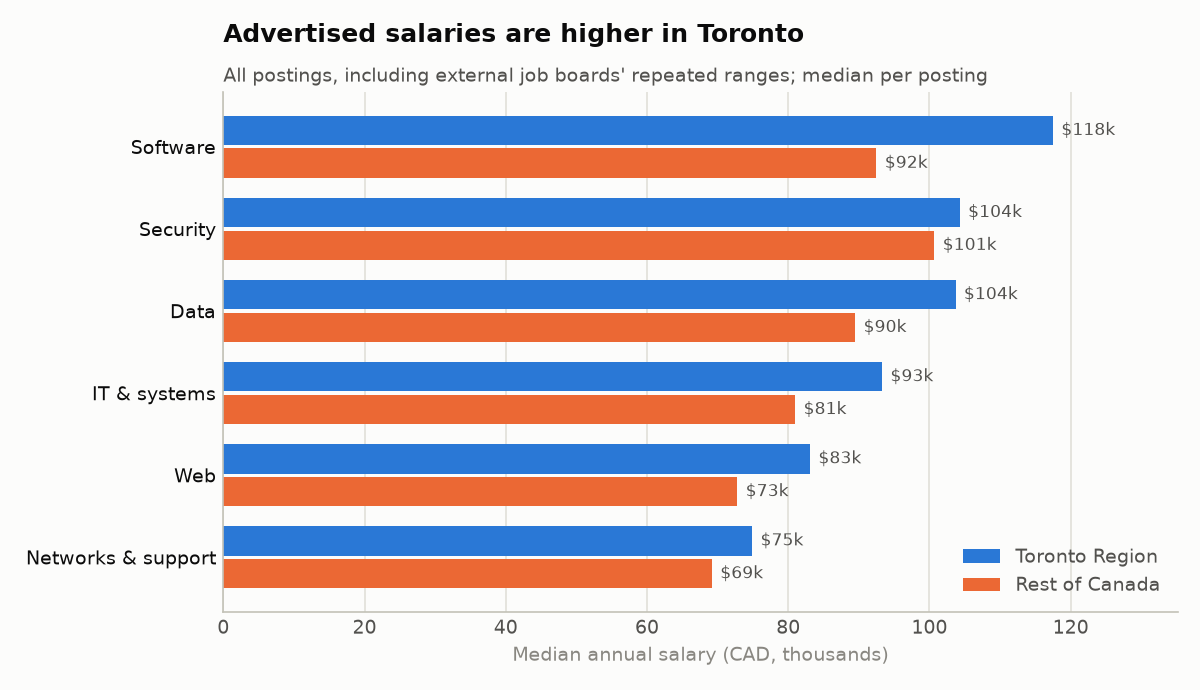

In [4]:
chart("03_salary_by_family")

**But a quarter of these salaries are templates, not real offers.** Some external job boards, which supply
most of the postings, attach the same wide range to every posting of an occupation: for example $30.00 to
$69.74 an hour for data scientists, which is about $62,000 to $145,000 a year. Such ranges cover 27% of the
Toronto tech postings that show a salary, and none of the postings that employers publish themselves.
A range that wide says little about what a specific job pays.

In [5]:
show(
    "10_repeated_salary_ranges",
    rename={
        "source": "Source",
        "postings_with_salary": "Postings with a salary",
        "in_repeated_ranges": "In template ranges",
        "repeated_pct": "Share (%)",
    },
)

Source,Postings with a salary,In template ranges,Share (%)
Direct employer postings,836,0,0
External job boards,"4,201","1,380",32.8
All,"5,037","1,380",27.4


**Looking only at postings that employers publish themselves, Toronto still pays more in five of six
families, but by much less**: software $95,000 versus $90,000, and data $90,000 versus $80,000. For web
roles, Toronto pays slightly *less* ($65,500 versus $68,300). These direct postings are fewer, so small
differences are uncertain.

In [6]:
show(
    "11_direct_salary_by_family",
    rename={
        "family": "Family",
        "toronto_postings": "Toronto postings",
        "toronto_median": "Toronto median",
        "rest_postings": "Rest of Canada postings",
        "rest_of_canada_median": "Rest of Canada median",
    },
)

Family,Toronto postings,Toronto median,Rest of Canada postings,Rest of Canada median
Networks & support,252,"67,300",623,"65,500"
Software,202,"95,000",430,"90,000"
IT & systems,166,"88,100",339,"82,500"
Web,95,"65,500",279,"68,300"
Data,93,"90,000",167,"80,000"
Security,29,"100,400",64,"97,300"


## 3. What do employers ask for?

Only postings that employers publish themselves state requirements, so this section is based on them.

**Most ask for a degree, but a college diploma is common too.** Half (51%) ask for a bachelor's degree, and
about 4 in 10 ask for a college diploma. A master's degree is rarely required (2%).

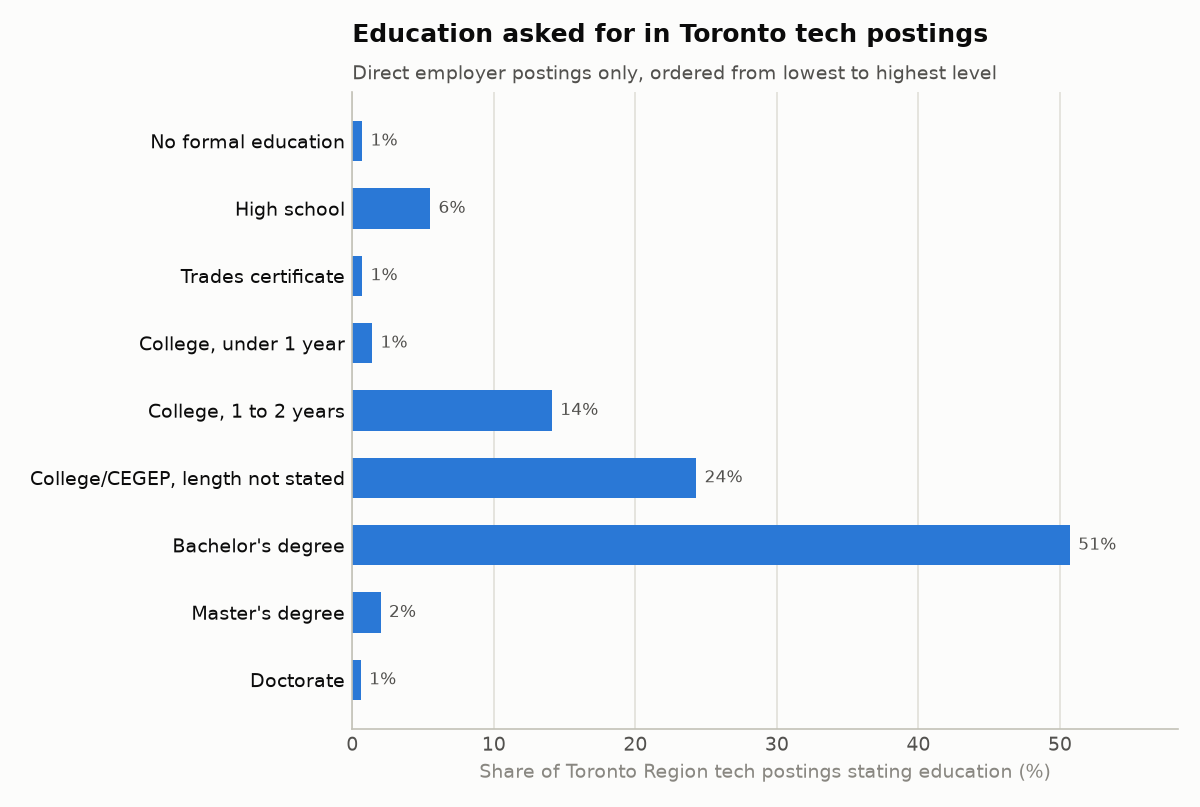

In [7]:
chart("06_toronto_education")

**Few postings are open to people without experience.** Only 7% ask for no experience and another 11% for
under a year. The most common requirement is 1 to 3 years (48% of postings).

In [8]:
show(
    "07_toronto_experience",
    rename={"experience": "Experience asked for", "postings": "Postings", "pct": "Share (%)"},
)

Experience asked for,Postings,Share (%)
None,62,7.4
Under 7 months,32,3.8
7 to 12 months,61,7.3
1 to 2 years,211,25.1
2 to 3 years,191,22.8
3 to 5 years,138,16.4
5 years or more,144,17.2


## 4. How does pay grow with experience?

**Pay rises clearly with the experience asked for.** Roles asking for up to two years have medians between
about $61,000 and $71,000. The median reaches $93,600 for 3 to 5 years and $109,200 for 5 years or more.
The first levels have few postings (32 to 62), so the small dip between "None" and "Under 7 months" is not
meaningful.

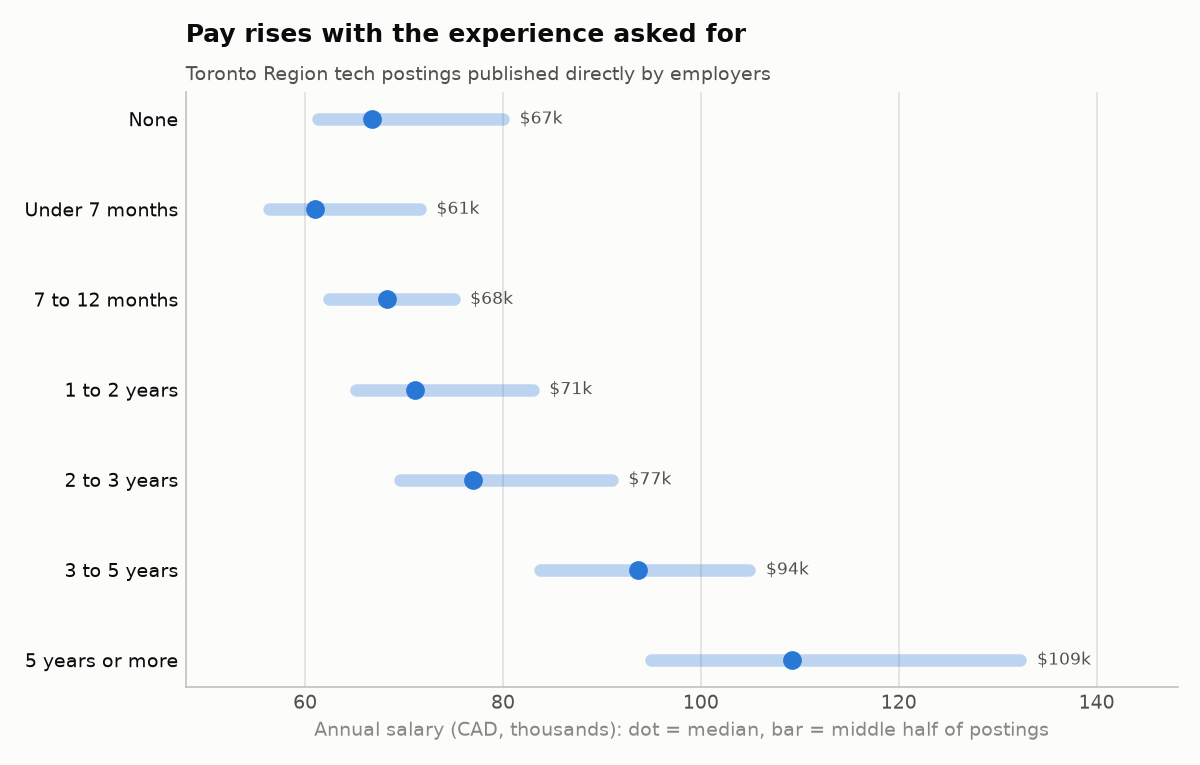

In [9]:
chart("09_toronto_salary_by_experience")

## 5. Is demand going up or down?

**Toronto's share of Canada's tech postings fell during the year**, from about half between December and
April to 38–43% between June and October, while postings in the rest of Canada held steadier. A single year
cannot tell whether this is a seasonal pattern or a lasting trend.

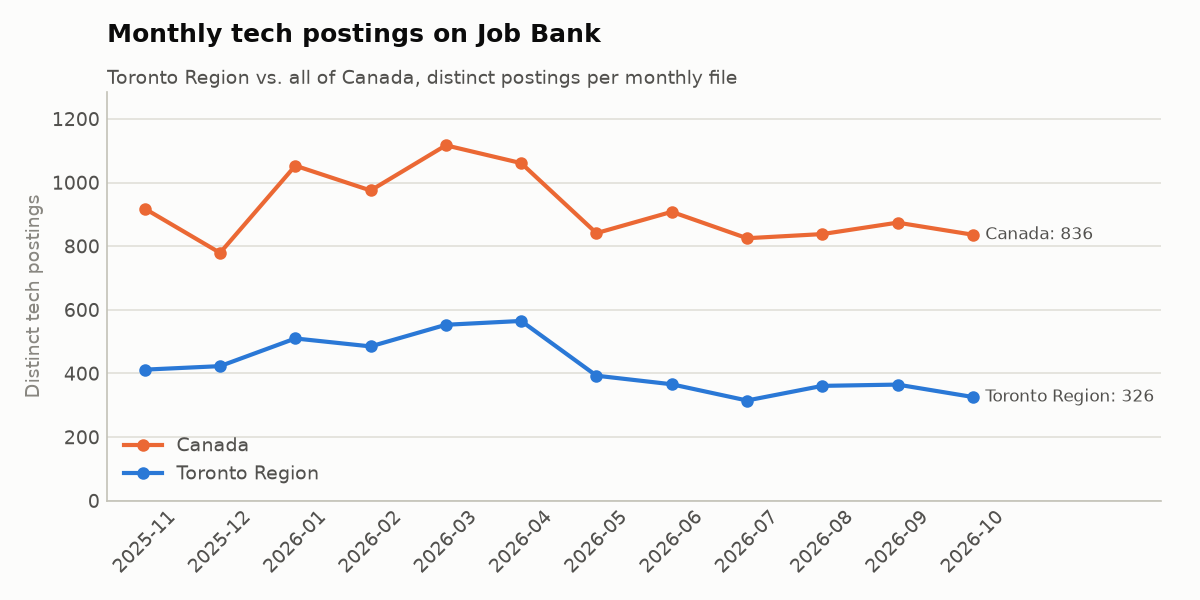

In [10]:
chart("05_monthly_trend")

## What this means if you are looking for a tech job in Toronto

- **Toronto is where most of the postings are,** especially for data and software roles.
- **Read advertised salary ranges with care.** A posting showing a very wide range may be using a template,
  so the midpoint is not a real offer. Postings from employers directly are a better guide: a typical
  software role there advertises about $95,000.
- **Experience matters more than an advanced degree.** Few postings require a master's degree, but most
  ask for at least a year of experience, and pay rises steeply after three years. For someone starting out,
  projects, internships and co-op terms that count as experience are worth as much as more study.
- **Expect competition for entry-level roles.** Fewer than 1 in 5 direct postings is open to people with
  under a year of experience.

These points describe Job Bank postings, not hires or actual salaries, and the data has no employer names,
so one large employer posting many similar ads can shift the numbers.

---

Contains information licensed under the
[Open Government Licence – Canada](https://open.canada.ca/en/open-government-licence-canada).
Source: [Job Postings Advertised on Canada's National Job Bank Website](https://open.canada.ca/data/en/dataset/ea639e28-c0fc-48bf-b5dd-b8899bd43072),
Employment and Social Development Canada.